# Qiskit Fall Fest 2026 - Calcolare il ground-state della molecola $H_2$

<div class="alert alert-info">
In questo notebook viene indagato il problema della ricerca del ground-state della molecola di diidrogeno e affrontato tramite una delle tecniche di diagonalizzazioni quantistiche più famose: la Variational Quantum Eigensolver. Per una trattazione più profonda e formale, non solo sulla VQE, ma anche sulle altre tecniche è possibile consultare i seguenti materiali:

* <a href="https://quantum.cloud.ibm.com/learning/en/courses/quantum-diagonalization-algorithms/introduction">Quantum diagonalization algorithms</a>
* <a href="https://quantum.cloud.ibm.com/docs/en/tutorials/sample-based-krylov-quantum-diagonalization">Sample-based Krylov quantum diagonalization of a fermionic lattice model</a>
</div>

## Obiettivi di apprendimento:
-   Comprendere il problema della ricerca del ground-state.
-   Comprendere la Variational Quantum Eigensolver (VQE).
-   Comprendere e saper analizzare i risultati dell'algoritmo.


## 0. Introduzione

Trovare gli autovalori ed autovettori dell'Hamiltoniana è un problema molto famoso e conosciuto all'interno della scienza ed è un problema in cui i computer quantistici trovano applicazione. Ma perché ci interessiamo alla diagonalizzazione di una matrice? Perché potenzialmente, i problemi reali di fisica, chimica e della scienza in generale, sono formulabili in termini matriciali e trovare autovalori e autovettori di una determinata matrice può essere estremamente utili in quanto rappresentano delle caratteristiche importanti. Un problema specifico che ci interessa risolvere è la ricerca del ground-state di un sistema fisico, ossia trovare il valore dello stato energetico fondamentale e, soprattutto, la sua configurazione. Questo problema è utile perché trovare il ground-state di un sistema fisico ci permette di capire (secondo debite approssimazioni) come lo troviamo in natura.

## 1. Setup dell'ambiente
Cominciamo installando ed importando tutti gli strumenti necessari. Le versioni di Python consigliate sono `3.12` e `3.13`.

In [ ]:
%pip install "numpy<2.5"
%pip install matplotlib
%pip install qiskit==2.5.2
%pip install qiskit-aer==0.17.2
%pip install qiskit-nature==0.8.0
%pip install qiskit-ibm-runtime==0.50.0
%pip install pyscf==2.14.0
%pip install scipy==1.15.3
%pip install ffsim==0.0.61

  Using cached pyscf-2.14.0-py3-none-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (6.6 kB)
Using cached pyscf-2.14.0-py3-none-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (52.8 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.3/37.3 MB 62.8 MB/s  0:00:00
  Attempting uninstall: scipy
    Found existing installation: scipy 1.16.3
    Uninstalling scipy-1.16.3:
      Successfully uninstalled scipy-1.16.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 3.4 MB/s  0:00:03


In [ ]:
from qiskit import QuantumCircuit
from qiskit_ibm_runtime.executor_estimator import Estimator
from qiskit_aer import AerSimulator

from qiskit.transpiler import PassManager
from qiskit.transpiler.passes import (
    Decompose,
    UnitarySynthesis,
    BasisTranslator,
    UnrollCustomDefinitions,
)
from qiskit.circuit.equivalence_library import SessionEquivalenceLibrary as sel

from qiskit_nature.second_q.circuit.library import UCCSD
from qiskit_nature.second_q.mappers import JordanWignerMapper
from ffsim.qiskit import PrepareHartreeFockJW

import pyscf
from pyscf import gto
from scipy.optimize import minimize
import ffsim

import numpy as np

import matplotlib.pyplot as plt

Imposteremo poi un backend (locale o remoto) sul quale imposteremo un oggetto `estimator` che utilizzeremo durante il notebook. In seguito, imposteremo un oggetto `pm` personalizzato per questo notebook, non è necessario approfondirne il funzionamento esatto, ci basti sapere che è quell'oggetto che transpilerà, secondo delle personalizzazioni, il circuito per il backend che abbiamo impostato.

In [ ]:
backend = AerSimulator()
estimator = Estimator(mode=backend)

pm = PassManager([
  Decompose(gates_to_decompose=["hartree_fock_jw"]),
  UnitarySynthesis(target=backend.target, method="default"),
  UnrollCustomDefinitions(equivalence_library=sel, target=backend.target),
  BasisTranslator(equivalence_library=sel, target=backend.target, target_basis=[
                  'cx', 'u2', 'rz', 'unitary', 'h', 'cp', 'sxdg']),
])

## 1.1 Concetti utili
Prima di procedere oltre, trattiamo brevemente alcuni concetti utili.
Introduciamo, innanzitutto, una caratteristica fondamentale e intrinseca delle particelle quantistiche: lo spin. Possiamo volgarmente pensare allo spin come a una direzione immaginaria dell’elettrone che può essere «sù» o «giù». Ogni orbitale molecolare può essere occupato al massimo da due elettroni, uno con spin up e uno con spin down.

Continuiamo poi trattando l'eccitazione di un elettrone, che è semplicemente il processo in cui uno o più elettroni «salgono» da orbitali occupati a orbitali vuoti.
Questo processo può avvenire in simultanea per più elettroni, quindi si parla di eccitazioni singole, doppie, triple e così via quando, rispettivamente, uno, due o tre elettroni «salgono» da orbitali occupati a orbitali vuoti. Più eccitazioni consideriamo (singole, doppie, triple, etc.) più i nostri calcoli diventano complessi.

In seguito, la trasformazione di Jordan-Wigner associa a ogni orbitale molecolare due qubit, uno per ciascun possibile spin dell'elettrone. Ciascun qubit indica se l'elettrone con quel determinato spin è presente ($|1\rangle$) oppure assente ($|0\rangle$).

**Esempio:** consideriamo una molecola con due orbitali molecolari, rappresentati da quattro qubit. Lo stato $|1100\rangle$ indica che il primo orbitale contiene due elettroni, uno con spin up e uno con spin down, mentre il secondo orbitale è vuoto.

Infine, trattiamo gli integrali a uno e due corpi che quantificano, rispettivamente:
* l'effetto dell'energia cinetica e del potenziale nucleare sugli elettroni;
* l'interazione diretta tra coppie di elettroni.

Entrambi i tipi di integrale sono necessari per descrivere la struttura di una molecola.

## 2. Definire il problema: la molecola $H_2$

### Esercizio 2.1

Creiamo innanzitutto la molecola sulla quale lavoreremo, per fare ciò, utilizzeremo il framework `PySCF`.
La molecola che creeremo avrà le seguenti caratteristiche:
* due nuclei a distanza di 1 Ångström ($1 \times 10^{-10}$ metri);
* set di basi STO-3G, ossia un insieme che contiene il numero minimo assoluto di orbitali utilizzati per descrivere il comportamento degli elettroni.

Hint: consultare la documentazione a questo link: https://pyscf.org/user/gto.html

In [ ]:
#TODO
mol = gto.Mole()
mol.build(
    atom = '''H  0 0 0; H 0 0 1''',
    basis = 'sto-3g')

### Esercizio 2.2

Dopo aver creato la molecola, bisogna definire lo spazio attivo cioè il numero di elettroni e orbitali. Questo spazio dovrà avere:
* 0 elettroni congelati (poiché non stiamo applicando l'approssimazione frozen-core);
* 2 elettroni attivi;
* 2 orbitali, cioè quindi uno per ogni elettrone attivo.

In seguito, dobbiamo definire:
* il numero di elettroni attivi con spin up e con spin down, che, in questo caso, devono essere uguali;
* il numero di qubit sulla base della mappatura di Jordan-Wigner.

In [ ]:
n_frozen = 0
n_electrons = 2
num_orbitals = 2

num_elec_up = 1
num_elec_down = 1
num_qubits = 2 * num_orbitals

nelec = (num_elec_up, num_elec_down)

active_space = range(n_frozen, n_electrons)

print(f"Number of active spatial orbitals: {num_orbitals}")
print(f"Number of active electrons: {n_electrons}")
print(f"Number of spin-up electrons: {num_elec_up}")
print(f"Number of spin-down electrons: {num_elec_down}")
print(f"Number of qubits: {num_qubits}")

Number of active spatial orbitals: 2
Number of active electrons: 2
Number of spin-up electrons: 1
Number of spin-down electrons: 1
Number of qubits: 4


La molecola appena creata è molto semplice, quindi è possibile calcolare numericamente il ground state e utilizzarlo come benchmark per i risultati della VQE.
Per fare ciò, utilizzeremo il metodo FCI del framework `PySCF`.

In [ ]:
scf = pyscf.scf.RHF(mol).run(verbose=0)
cas = pyscf.mcscf.CASCI(scf, num_orbitals, nelec)
mo = cas.sort_mo(active_space, base=0)
fci_result = cas.run(mo, verbose=0)
exact_fci_energy = fci_result.e_tot

print(f"Exact total ground-state energy (FCI): {exact_fci_energy:.6f} Ha")

Exact total ground-state energy (FCI): -1.101150 Ha


### 2.1 Associare il problema fisico a dei qubit

Per costruire l'Hamiltoniana del sistema dobbiamo per prima cosa associare il problema fisico a dei qubit. Questo non è, generalmente, un compito semplice e richiederebbe un corso a parte. In questo notebook, ci basti sapere che utilizzeremo la trasformazione di Jordan-Wigner.

Ora, utilizzeremo il framework `ffsim` per ottenere l'Hamiltoniana di cui ci interessa stimare il valore medio, per tradurla in un operatore fermionico (che riassume matematicamente processi come: aggiungere o rimuovere un elettrone da uno stato elettronico, descrivere il movimento degli elettroni, descrivere le interazioni tra elettroni) e per applicare la trasformazione di Jordan-Wigner a questo operatore.

In [ ]:
one_body_integrals, nuclear_repulsion_energy = cas.get_h1cas(mo)
two_body_integrals = pyscf.ao2mo.restore(1, cas.get_h2cas(mo), num_orbitals)

mol_hamiltonian = ffsim.MolecularHamiltonian(
    one_body_tensor=one_body_integrals, two_body_tensor=two_body_integrals)
ferm_op = ffsim.fermion_operator(mol_hamiltonian)
hamiltonian = ffsim.qiskit.jordan_wigner(ferm_op)

## 3. All'opera con VQE

Il VQE è un algoritmo ibrido quantistico-classico, appartenente alla famiglia dei Variational Quantum Algorithms, che approssima l’autovalore minimo $E_0$ di un’Hamiltoniana $H$ e il relativo autovettore $|\psi\rangle_0$ (il ground-state). L’idea è trasformare un problema di diagonalizzazione, impraticabile per matrici di dimensione $2^n$, in un problema di minimizzazione di una funzione di pochi parametri reali.

**Intuizione**  
L’energia è un paesaggio con colline e valli; il ground-state è il punto più basso. Non possiamo esplorare tutto il paesaggio (lo spazio di Hilbert a $2^n$ dimensioni), quindi scegliamo una famiglia parametrizzata di stati (l’*ansatz*) e lasciamo che un ottimizzatore classico cerchi il minimo al suo interno.

### I quattro ingredienti del VQE

1. **Operatore quantistico (Hamiltoniana)**  
   Descrive la proprietà del sistema che vogliamo ottimizzare. Dopo la mappatura su qubit è una somma pesata di operatori di Pauli.

2. **Ansatz**  
   Un circuito quantistico parametrico che prepara lo stato di prova a partire da uno stato di riferimento (spesso lo stato di Hartree-Fock). I parametri sono tipicamente angoli di rotazione all’interno di gate a uno o due qubit.

3. **Stimatore**  
   Calcola il valore di aspettazione dell’Hamiltoniana per un dato insieme di parametri. Poiché i termini di Pauli non commutano tutti tra loro, lo stimatore raggruppa le misure e le combina statisticamente.

4. **Ottimizzatore classico**  
   Aggiorna i parametri secondo un’euristica (COBYLA, L-BFGS-B, SPSA, …) cercando di minimizzare l’energia stimata.

<details>
<summary><b>📐 Matematica formale degli ingredienti (clicca per espandere)</b></summary>

#### Hamiltoniana su qubit
Dopo la trasformazione di Jordan-Wigner (o un’altra mappatura) l’operatore assume la forma
$$
H = \sum_i c_i P_i
$$
dove $c_i \in \mathbb{R}$ e $P_i$ è una stringa di operatori di Pauli agenti sui qubit.

#### Ansatz
Lo stato di prova è
$$
|\psi(\vec\theta)\rangle = U(\vec\theta)\,|\psi_0\rangle
$$
con $U(\vec\theta)$ circuito parametrico e $|\psi_0\rangle$ stato di riferimento (tipicamente Hartree-Fock).

#### Stimatore
Il valore di aspettazione è stimato come
$$
\langle H\rangle_{\vec\theta} \approx \frac{1}{N}\sum_{j=1}^{N} E_j
$$
(il risultato diventa esatto per $N\to\infty$ in assenza di rumore). Lo stimatore si occupa anche di raggruppare i termini di Pauli che commutano.

#### Principio variazionale
Sia $H$ hermitiana con autostati $\{|\phi_k\rangle\}$ e autovalori $E_0\le E_1\le\dots$. Per ogni stato normalizzato $|\psi\rangle=\sum_k c_k|\phi_k\rangle$:
$$
\langle\psi|H|\psi\rangle = \sum_k |c_k|^2 E_k \;\ge\; E_0\sum_k|c_k|^2 = E_0.
$$
L’uguaglianza vale se e solo se $|\psi\rangle$ appartiene all’autospazio fondamentale. Minimizzare $\langle H\rangle$ su una famiglia di stati equivale quindi a cercare la migliore approssimazione di $|\phi_0\rangle$ all’interno di quella famiglia (metodo di Rayleigh-Ritz).

#### Complessità
- Classicamente la diagonalizzazione completa di una matrice $2^n\times 2^n$ costa $O(2^{3n})$ (o $O(2^{2n})$ con metodi iterativi).
- Nel VQE il costo quantistico scala con la precisione richiesta e con il numero di termini di Pauli, non quadraticamente con la dimensione dello spazio di Hilbert.

</details>

### Vantaggi e limiti

| Vantaggi | Limiti |
|----------|--------|
| Utilizzabile su hardware NISQ | Non garantisce la convergenza al minimo globale |
| Circuiti relativamente poco profondi | Ansatz troppo espressivi diventano costosi |
| Estremamente versatile | Barren plateaus (gradienti che spariscono) con molti parametri |
| Principio variazionale fornisce un bound superiore rigoroso | Sensibile al rumore hardware |


### Esercizio 3.1
Impostiamo gli iperparametri dell'algoritmo, vogliamo in particolare:
* $50$ iterazioni massime;
* una tolleranza pari a $1 \times 10^{-6}$;
* ottimizzatore COBYLA.

In [ ]:
# --- Parametri dell'algoritmo ---
max_iterations = 50
tolerance = 1e-6
optimizer_name = "cobyla"

### Esercizio 3.2
Dobbiamo ora costruire uno stato di riferimento iniziale e, su questo, costruire uno stato quantistico che descrive come si comportano gli elettroni.

Nello specifico, vorremmo:
* impostare lo stato di Hartree-Fock come stato iniziale di riferimento;
* impostare lo stato quantistico dato dall'ansatz UCCSD come lo stato che descrive il comportamento degli elettroni con la mappatura di Jordan-Wigner.

Hint: abbiamo importato due oggetti specifici con un nome caratteristico, usare quelli in accordo alla documentazione.

In [ ]:
from qiskit_nature.second_q.circuit.library import HartreeFock
from qiskit_nature.second_q.circuit.library import UCCSD
mapper = JordanWignerMapper()

initial_state = HartreeFock(
    num_spatial_orbitals=num_orbitals,
    num_particles=nelec,
    qubit_mapper=mapper
)

ansatz = UCCSD(
    num_spatial_orbitals=num_orbitals,
    num_particles=nelec,
    qubit_mapper=mapper,
    initial_state=initial_state
)

print(f"Numero di qubit dell'ansatz : {ansatz.num_qubits}")
print(f"Numero di parametri         : {ansatz.num_parameters}")

Numero di qubit dell'ansatz : 4
Numero di parametri         : 3


Adesso costruiamo la funzione da ottimizzare, essa lavorerà con un oggetto di nome `pub` che è quello su cui lavorerà l'oggetto `estimator` che alla fine ci restituirà in output l'energia stimata del sistema.

In [ ]:
def evaluate_energy(parameters):
  pub = (variational_circuit_isa, [hamiltonian_isa], [parameters])
  result = estimator.run(pubs=[pub]).result()
  energy = float(result[0].data.evs[0])

  energy += nuclear_repulsion_energy

  cost_history["iters"] += 1
  cost_history["prev_vector"] = parameters
  cost_history["cost_history"].append(energy)
  print(
      f"Iters. done: {cost_history['iters']:3d}  [Current cost: {energy:.8f} Ha]")
  return energy

### Esercizio 3.3
Infine, mettiamo insieme tutto, dovremo:
* inizializzare un circuito con un numero di qubit e bit classici pari ai qubit dell'Hamiltoniana;
* comporre il circuito con stato iniziale ed ansatz, in quest'ordine;
* transpilare il circuito con l'oggetto `pm` instanziato all'inizio;
* inizializzare i parametri `x0` tutti a $0$, hint: `x0` è una lista numerica la cui grandezza è pari al numero di parametri del circuito.

In [ ]:
variational_circuit = QuantumCircuit(hamiltonian.num_qubits, hamiltonian.num_qubits)

variational_circuit.compose(initial_state, inplace=True)
variational_circuit.compose(ansatz, inplace=True)

variational_circuit_isa = pm.run(variational_circuit)

# Applichiamo lo stesso layout del circuito transpilato all'Hamiltoniana,
# in modo che entrambi abbiano la stessa "forma"
hamiltonian_isa = hamiltonian.apply_layout(
    layout=variational_circuit_isa.layout)

x0 = [0] * variational_circuit_isa.num_parameters

cost_history = {
    "iters": 0,
    "prev_vector": None,
    "cost_history": [],
}

result = minimize(
    evaluate_energy,
    x0,
    method=optimizer_name,
    tol=tolerance,
    options={"maxiter": max_iterations},
)

Iters. done:   1  [Current cost: 0.52720738 Ha]
Iters. done:   2  [Current cost: 0.52766381 Ha]
Iters. done:   3  [Current cost: 0.52994592 Ha]
Iters. done:   4  [Current cost: 0.52900905 Ha]
Iters. done:   5  [Current cost: 0.52804816 Ha]
Iters. done:   6  [Current cost: 0.52840850 Ha]
Iters. done:   7  [Current cost: 0.52980179 Ha]
Iters. done:   8  [Current cost: 0.52994592 Ha]
Iters. done:   9  [Current cost: 0.52898503 Ha]
Iters. done:  10  [Current cost: 0.52934537 Ha]
Iters. done:  11  [Current cost: 0.52595822 Ha]
Iters. done:  12  [Current cost: 0.52869677 Ha]
Iters. done:  13  [Current cost: 0.52965766 Ha]
Iters. done:  14  [Current cost: 0.52872079 Ha]
Iters. done:  15  [Current cost: 0.52953755 Ha]
Iters. done:  16  [Current cost: 0.52855263 Ha]
Iters. done:  17  [Current cost: 0.53059453 Ha]
Iters. done:  18  [Current cost: 0.52874481 Ha]
Iters. done:  19  [Current cost: 0.53095486 Ha]
Iters. done:  20  [Current cost: 0.53198782 Ha]
Iters. done:  21  [Current cost: 0.53057

### Esercizio 3.4
Adesso visualizzeremo i risultati.

Domande:
* Cosa possiamo dire sulla curva che percorre l'algoritmo?
* Quali prestazioni ha avuto rispetto ai metodi classici?

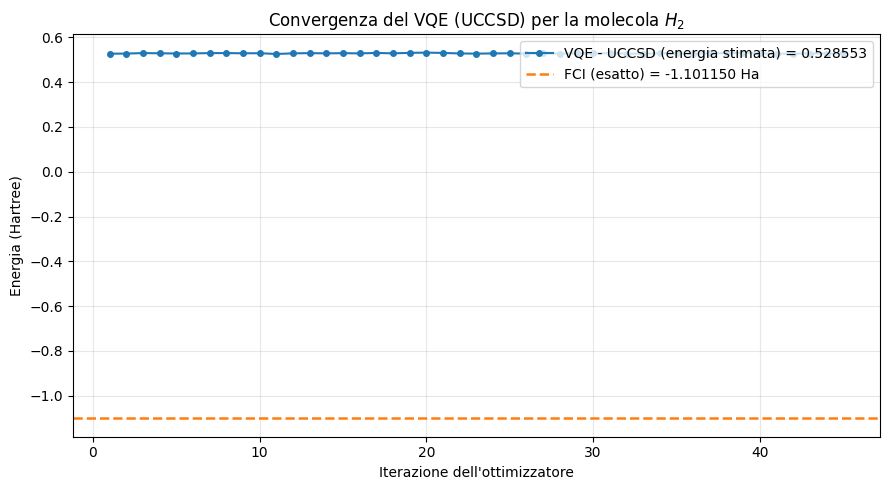

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))

iters = range(1, len(cost_history["cost_history"]) + 1)
ax.plot(iters, cost_history["cost_history"], "o-", color="C0",
        markersize=4, label=f"VQE - UCCSD (energia stimata) = {cost_history['cost_history'][-1]:.6f}")

ax.axhline(exact_fci_energy, color="C1", linestyle="--", linewidth=1.8,
           label=f"FCI (esatto) = {exact_fci_energy:.6f} Ha")

ax.set_xlabel("Iterazione dell'ottimizzatore")
ax.set_ylabel("Energia (Hartree)")
ax.set_title(r"Convergenza del VQE (UCCSD) per la molecola $H_2$")
ax.legend(loc="upper right")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
#1) L'algoritmo parte dall'energia dello stato di Hartree-Fock e scende progressivamente fino a stabilizzarsi su un plateau in poche iterazioni.
#2) Sebbene su una molecola così piccola il calcolo classico sia molto più veloce, su molecole grandi l'FCI diventa computazionalmente intrattabile

# Conclusione
Questa è la fine del notebook, noi dell'organizzazione speriamo l'abbiate apprezzato e che soprattutto abbiate compreso il problema e l'algoritmo. Vogliamo ricordarvi che questo è solo UNO degli algoritmi esistenti per affrontare questo tipo di problemi, se vi va, vi invitiamo ad approfondirli. Vogliamo inoltre precisare che l'esecuzione di questo algoritmo è avvenuta all'interno di un simulatore ideale e che, se doveste eseguire questo circuito su un vero computer quantistico andrete incontro al rumore, una cosa che richiede altre lezioni per spiegare come gestirla.

Grazie per la vostra attenzione!